In [1]:
import pandas as pd
import requests

# 天気APIから取得
res = requests.get(
    "https://api.open-meteo.com/v1/forecast",
    params={
        "latitude": 38.2682,
        "longitude": 140.8694,
        "daily": ["temperature_2m_max", "temperature_2m_min"],
        "timezone": "Asia/Tokyo",
        "past_days": 7,
    },
    timeout=10,
)
daily = res.json()["daily"]

# 表にして加工
df = pd.DataFrame({
    "date": daily["time"],
    "temp_max": daily["temperature_2m_max"],
    "temp_min": daily["temperature_2m_min"],
})
df["temp_diff"] = df["temp_max"] - df["temp_min"]
print(df)

          date  temp_max  temp_min  temp_diff
0   2026-11-18      17.7       6.6       11.1
1   2026-11-19      12.3       4.3        8.0
2   2026-11-20       6.2       2.9        3.3
3   2026-11-21       7.6       1.5        6.1
4   2026-11-22       9.4       1.4        8.0
5   2026-11-23      10.6       2.8        7.8
6   2026-11-24      15.0       4.2       10.8
7   2026-11-25       7.0       3.1        3.9
8   2026-11-26      14.8       3.4       11.4
9   2026-11-27      17.2       7.6        9.6
10  2026-11-28      11.0       6.3        4.7
11  2026-11-29       7.0       3.4        3.6
12  2026-11-30      13.3       1.9       11.4
13  2026-12-01      17.6       7.2       10.4


In [2]:
from google.colab import auth
import pandas_gbq

auth.authenticate_user()

pandas_gbq.to_gbq(
    dataframe=df,
    destination_table="weather_demo.daily_temp",
    project_id="gen-lang-client-0488662860",
    if_exists="replace",
)
print("完了！")

100%|██████████| 1/1 [00:00<00:00, 8886.24it/s]

完了！


Downloading: 100%|██████████|
  diff_category  days_count  avg_temp_diff
0  中くらい（5〜9.9℃）           5            7.9
1    大きい（10℃以上）           5           11.0
2     小さい（5℃未満）           4            3.9


/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 12367 (\N{HIRAGANA LETTER KU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 12425 (\N{HIRAGANA LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 12356 (\N{HIRAGANA LETTER I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 12316 (\N{WAVE DASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1668/1815412511.py:26: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt

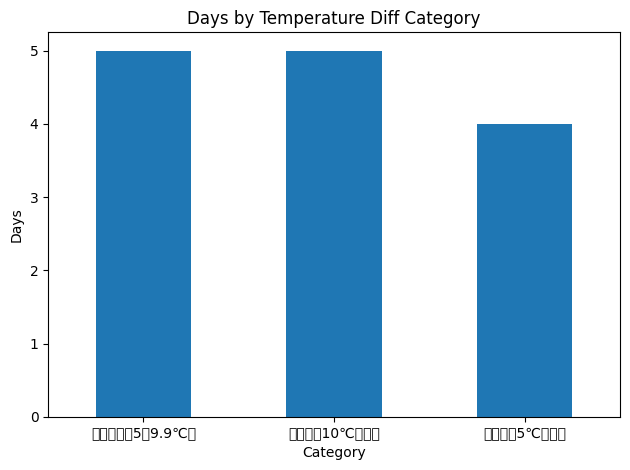

In [3]:
import pandas as pd
import pandas_gbq
import matplotlib.pyplot as plt

# 日本語文字化け防止（環境によっては四角になることがあるのでまずはシンプルに英語ラベルや確認用で実行）
query = """
SELECT
  diff_category,
  days_count,
  avg_temp_diff
FROM
  `gen-lang-client-0488662860.weather_demo.mart_diff_summary`
ORDER BY
  days_count DESC
"""

df_mart = pandas_gbq.read_gbq(query, project_id="gen-lang-client-0488662860")
print(df_mart)

# 棒グラフを描画
ax = df_mart.plot(kind="bar", x="diff_category", y="days_count", legend=False)
ax.set_title("Days by Temperature Diff Category")
ax.set_xlabel("Category")
ax.set_ylabel("Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import requests

cities = [
    {"city": "Sendai", "lat": 38.2682, "lon": 140.8694},
    {"city": "Tokyo", "lat": 35.6762, "lon": 139.6503},
    {"city": "Osaka", "lat": 34.6937, "lon": 135.5023},
]

dfs = []
for c in cities:
    res = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": c["lat"],
            "longitude": c["lon"],
            "daily": ["temperature_2m_max", "temperature_2m_min"],
            "timezone": "Asia/Tokyo",
            "past_days": 7,
        },
        timeout=10,
    )
    daily = res.json()["daily"]
    temp_df = pd.DataFrame({
        "city": c["city"],
        "date": daily["time"],
        "temp_max": daily["temperature_2m_max"],
        "temp_min": daily["temperature_2m_min"],
    })
    temp_df["temp_diff"] = temp_df["temp_max"] - temp_df["temp_min"]
    dfs.append(temp_df)

df_all = pd.concat(dfs, ignore_index=True)
print("行数:", len(df_all))
print(df_all.head(10))

行数: 42
     city        date  temp_max  temp_min  temp_diff
0  Sendai  2026-11-18      17.7       6.6       11.1
1  Sendai  2026-11-19      12.3       4.3        8.0
2  Sendai  2026-11-20       6.2       2.9        3.3
3  Sendai  2026-11-21       7.6       1.5        6.1
4  Sendai  2026-11-22       9.4       1.4        8.0
5  Sendai  2026-11-23      10.6       2.8        7.8
6  Sendai  2026-11-24      15.0       4.2       10.8
7  Sendai  2026-11-25       7.5       3.1        4.4
8  Sendai  2026-11-26      14.7       3.3       11.4
9  Sendai  2026-11-27      16.9       7.8        9.1


In [6]:
from google.colab import auth
import pandas_gbq

auth.authenticate_user()

pandas_gbq.to_gbq(
    dataframe=df_all,
    destination_table="weather_demo.daily_temp_cities",
    project_id="gen-lang-client-0488662860",
    if_exists="replace",
)
print("3都市データの書き込み完了！")

100%|██████████| 1/1 [00:00<00:00, 9731.56it/s]

3都市データの書き込み完了！
